# 0Análisis Espacio-Temporal: Rezagos Biológicos, Autocorrelación y Dependencia entre Cantones

1. **¿Qué tamaño de ventana temporal $T_{\text{in}}$ necesitamos?** (Autocorrelación de `casos` por cantón).
2. **¿Qué covariables climáticas / ENSO / Google Trends tienen señal real y con cuántas semanas de rezago?** (Calculado **estrictamente en `train <= 2023`** para evitar fuga de datos).
3. **¿Existe co-movimiento espacial entre cantones?** (Matriz de correlación $82 \times 82$ como evidencia previa a la matriz de adyacencia $W$).

In [ ]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow

In [ ]:
sns.set_theme(style="whitegrid", context="notebook")

ROOT_DIR = Path.cwd()
if ROOT_DIR.name == "notebooks":
    ROOT_DIR = ROOT_DIR.parent
os.chdir(ROOT_DIR)

df = pd.read_csv(ROOT_DIR / "data/processed/dengue_panel_clean.csv")
df = df.sort_values(["canton", "time_idx"]).reset_index(drop=True)

train_df = df[df["year"] <= 2023].copy()
val_df = df[df["year"] == 2024].copy()
test_df = df[df["year"] == 2025].copy()

print(f"Train: {train_df.shape} | Val: {val_df.shape} | Test: {test_df.shape}")

Train: (16400, 35) | Val: (4264, 35) | Test: (4264, 35)


/home/jonathan.aragonportillo/bin/conda/envs/llm_rag/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Autocorrelación temporal: ¿cuántas semanas hacia atrás mirar ($T_{\text{in}}$)?

Calculamos la autocorrelación de `casos` (y `log1p(casos)`) dentro de cada cantón en `train` para rezagos de 1 a 16 semanas y también en el rezago estacional de 52 semanas.

En la siguiente figura observamos que la ventana de contexto que deberíamos de tomar entre 8 a 12 semanas, dado que son aquellos donde se llegan a unir la tres medidas más cercanas.

,lag,pearson_casos,spearman_casos,pearson_log1p
0,1,0.946,0.727,0.885
1,2,0.910,0.699,0.860
2,3,0.868,0.682,0.842
3,4,0.828,0.668,0.826
4,5,0.788,0.657,0.809
5,6,0.749,0.638,0.785
6,7,0.717,0.622,0.767
7,8,0.674,0.612,0.746
8,9,0.628,0.597,0.725
9,10,0.578,0.589,0.704


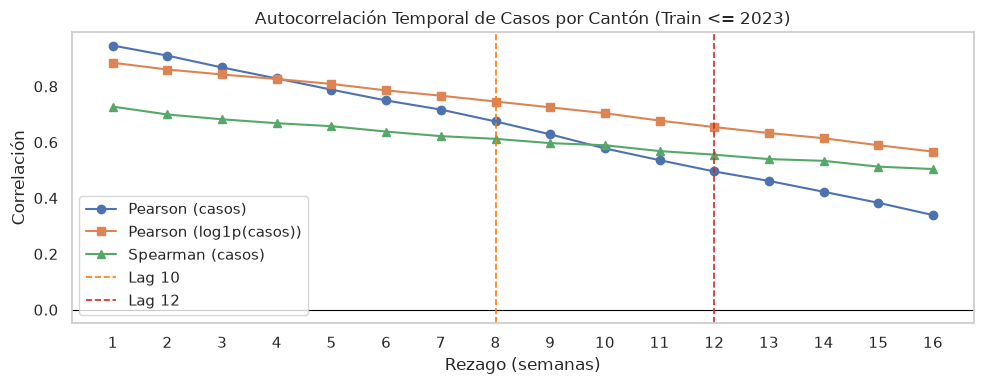

In [6]:
lags = list(range(1, 17)) + [52]
train_df["log_casos"] = np.log1p(train_df["casos"])

acf_rows = []
for k in lags:
    s_raw = train_df.groupby("canton")["casos"].shift(k)
    s_log = train_df.groupby("canton")["log_casos"].shift(k)
    acf_rows.append({
        "lag": k,
        "pearson_casos": train_df["casos"].corr(s_raw, method="pearson"),
        "spearman_casos": train_df["casos"].corr(s_raw, method="spearman"),
        "pearson_log1p": train_df["log_casos"].corr(s_log, method="pearson"),
    })

acf_df = pd.DataFrame(acf_rows)
display(acf_df.round(3))

fig, ax = plt.subplots(figsize=(10, 4))
sub = acf_df[acf_df["lag"] <= 16]
ax.plot(sub["lag"], sub["pearson_casos"], marker="o", label="Pearson (casos)")
ax.plot(sub["lag"], sub["pearson_log1p"], marker="s", label="Pearson (log1p(casos))")
ax.plot(sub["lag"], sub["spearman_casos"], marker="^", label="Spearman (casos)")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(1, 17))
ax.set_title("Autocorrelación Temporal de Casos por Cantón (Train <= 2023)")
ax.set_xlabel("Rezago (semanas)")
ax.set_ylabel("Correlación")
ax.axvline(8, color="#ff7f0e", ls="--", lw=1.2, label="Lag 10")
ax.axvline(12, color="#d62728", ls="--", lw=1.2, label="Lag 12")
ax.grid(False)
ax.legend()
fig.tight_layout()
fig_acf = ROOT_DIR / "data/processed/eda/04_autocorrelacion_lags.png"
fig.savefig(fig_acf, dpi=150)
plt.show()

## 2. Señal predictiva de covariables a distintos rezagos

En epidemiología del dengue, la lluvia o la temperatura de hoy **no** generan casos hoy: primero aumentan los criaderos, madura el *Aedes aegypti* y ocurre la incubación (aprox. 2 a 8 semanas). 

Evaluamos en `train` qué covariables tienen mayor correlación de Spearman con `casos` en $t$ cuando se observan en $t - k$ ($k = 1, \dots, 12$).

En la siguiente figura, se observa que las variables, a nivel país, tienen una alta relación, las cuales son temp_prom, tmin_mean y tmax_mean, e inclusive el fenomeno del niño. Sin embargo, si lo observamos a nivel de tiempo, realmente no hay un pico a nivel de tiempo de semanas posteriores, sino que está plano. No debemos olvidar que no todos los cantones
tienen casos ceros y no se comportan igual en todos, esto indica que hay que hacer un revisión de los datos de manera indivual por cantón.

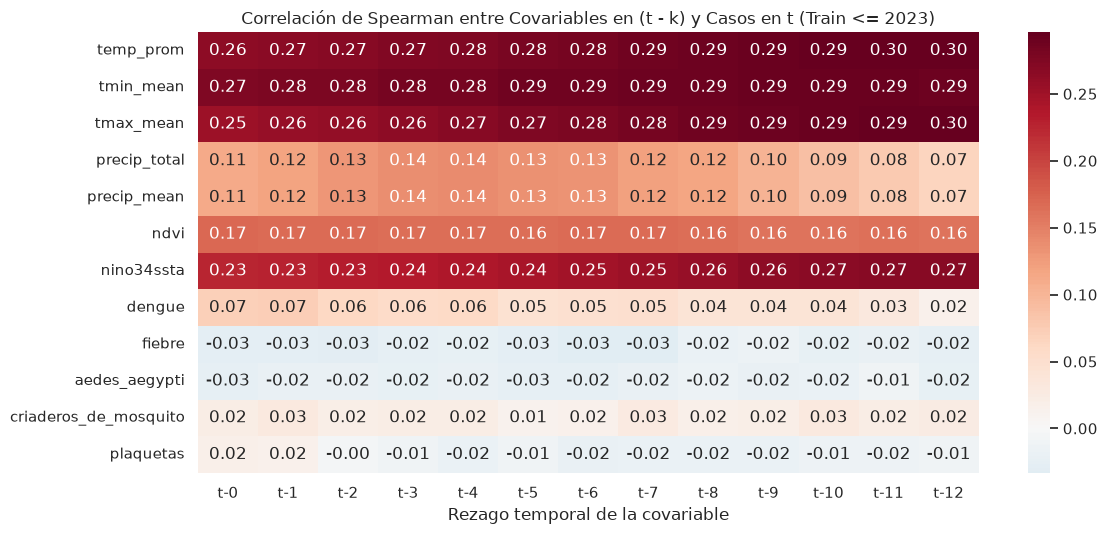

In [12]:
candidate_covs = [
    "temp_prom", "tmin_mean", "tmax_mean",
    "precip_total", "precip_mean", "ndvi", "nino34ssta",
    "dengue", "fiebre", "aedes_aegypti", "criaderos_de_mosquito", "plaquetas"
]

lag_range = range(0, 13)
corr_mat = pd.DataFrame(index=candidate_covs, columns=[f"t-{k}" for k in lag_range], dtype=float)

for cov in candidate_covs:
    for k in lag_range:
        shifted = train_df.groupby("canton")[cov].shift(k) if k > 0 else train_df[cov]
        corr_mat.loc[cov, f"t-{k}"] = train_df["casos"].corr(shifted, method="spearman")

fig, ax = plt.subplots(figsize=(12, 5.5))
sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Correlación de Spearman entre Covariables en (t - k) y Casos en t (Train <= 2023)")
ax.set_xlabel("Rezago temporal de la covariable")
fig.tight_layout()
fig_cov = ROOT_DIR / "data/processed/eda/05_correlacion_covariables_rezagos.png"
fig.savefig(fig_cov, dpi=150)
plt.show()

## 3. Dependencia espacial entre los 82 cantones

Si el dengue se propaga espacialmente entre cantones vecinos y corredores regionales, las series `log1p(casos)` de cantones cercanos deberían mostrar correlación positiva.  
Construimos la matriz cantón × semana en `train` y visualizamos la correlación entre los 82 cantones ordenados por provincia (`1xx` San José ... `7xx` Limón).

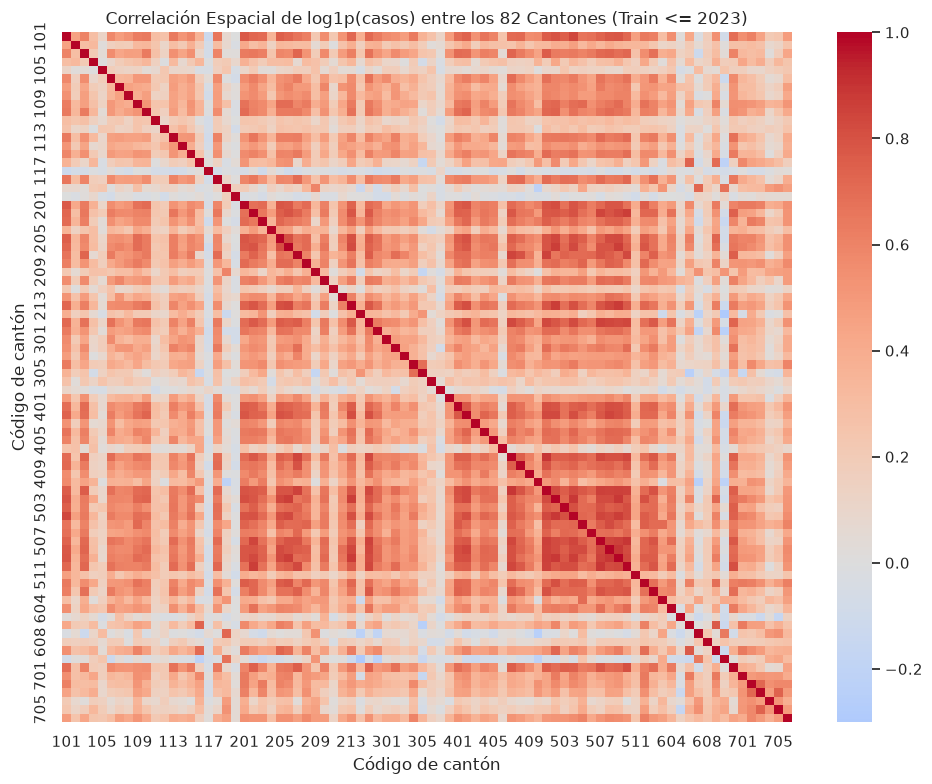

In [13]:
pivot_log = train_df.pivot(index="time_idx", columns="canton", values="log_casos")
spatial_corr = pivot_log.corr(method="pearson")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(spatial_corr, cmap="coolwarm", center=0, vmin=-0.3, vmax=1.0, xticklabels=4, yticklabels=4, ax=ax)
ax.set_title("Correlación Espacial de log1p(casos) entre los 82 Cantones (Train <= 2023)")
ax.set_xlabel("Código de cantón")
ax.set_ylabel("Código de cantón")
fig.tight_layout()
fig_sp = ROOT_DIR / "data/processed/eda/06_correlacion_espacial_cantones.png"
fig.savefig(fig_sp, dpi=150)
plt.show()

In [14]:
# Resumen numérico de conectividad espacial empírica
upper = spatial_corr.where(np.triu(np.ones(spatial_corr.shape), k=1).astype(bool))
pairs_gt_05 = int((upper > 0.5).sum().sum())
mean_off_diag = float(upper.stack().mean())
print(f"Correlación promedio entre pares de cantones: {mean_off_diag:.3f}")
print(f"Pares de cantones con correlación > 0.50: {pairs_gt_05} / {82*81//2}")

Correlación promedio entre pares de cantones: 0.358
Pares de cantones con correlación > 0.50: 1082 / 3321


### 3.1 Clustering Espacio-Temporal de los 82 Cantones

En este gráfico podemos observar cantones que están altamente asociados a nivel cantón durante todo el año. En es gráfico se identifica que 3 grupos:

1) Todo el año tienen casos de dengue.
2) Un grupo comienza con casos, luego reducen y finalizando el año empienzan aumentar.
3) Otros que solo a finales del año tienen picos de dengue.

/home/jonathan.aragonportillo/bin/conda/envs/llm_rag/lib/python3.11/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


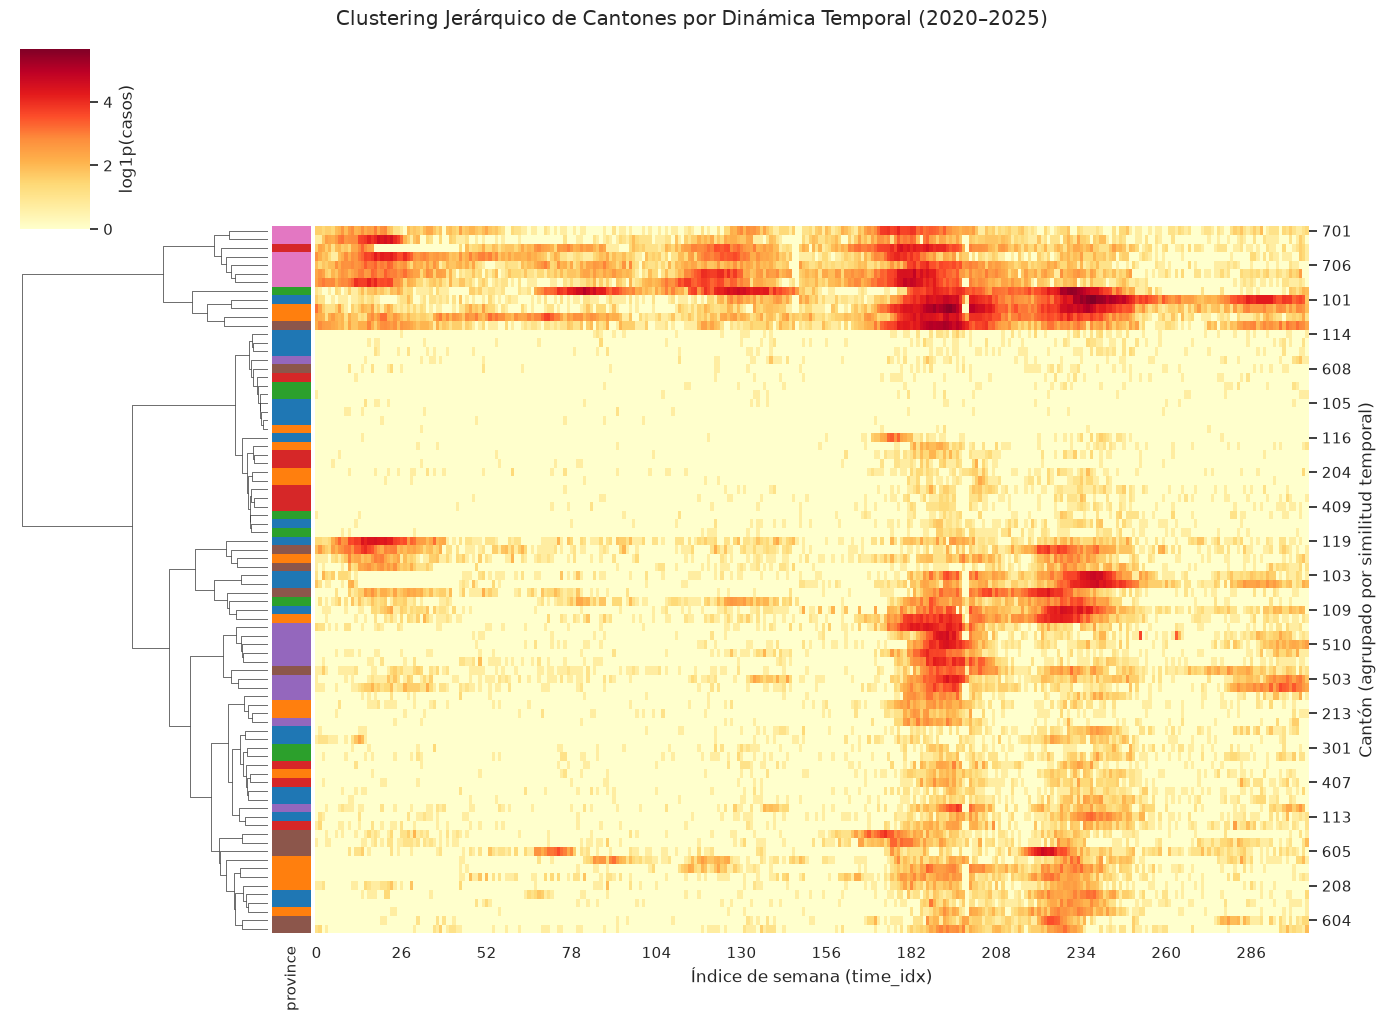

In [16]:
df_full_log = df.assign(log_casos=np.log1p(df["casos"]))
mat_canton_time = df_full_log.pivot(index="canton", columns="time_idx", values="log_casos")

prov_map = df.groupby("canton")["province"].first()
palette = sns.color_palette("tab10", n_colors=7)
prov_colors = prov_map.map({p: palette[p - 1] for p in range(1, 8)})

g = sns.clustermap(
    mat_canton_time,
    col_cluster=False,
    row_cluster=True,
    method="ward",
    metric="euclidean",
    cmap="YlOrRd",
    row_colors=prov_colors,
    figsize=(14, 10),
    xticklabels=26,
    yticklabels=4,
    cbar_kws={"label": "log1p(casos)"},
)
g.fig.suptitle("Clustering Jerárquico de Cantones por Dinámica Temporal (2020–2025)", y=1.02)
g.ax_heatmap.set_xlabel("Índice de semana (time_idx)")
g.ax_heatmap.set_ylabel("Cantón (agrupado por similitud temporal)")

fig_cluster = ROOT_DIR / "data/processed/eda/07_clustering_espacio_temporal.png"
g.savefig(fig_cluster, dpi=150, bbox_inches="tight")
plt.show()

In [17]:
mlruns_dir = (ROOT_DIR / "mlruns").resolve()
tracking_uri = f"sqlite:///{(mlruns_dir / 'mlflow.db').as_posix()}"
mlflow.set_tracking_uri(tracking_uri)
mlflow.set_experiment("dengue_cr_spatiotemporal")

with mlflow.start_run(run_name="01_eda_spatiotemporal_signals"):
    mlflow.set_tags({"stage": "eda_spatiotemporal", "split": "train_only_<=2023"})
    mlflow.log_params({"max_lag_checked": 16, "spatial_nodes": 82})
    mlflow.log_metrics({
        "acf_lag1_pearson": round(float(acf_df.loc[acf_df["lag"] == 1, "pearson_casos"].iloc[0]), 4),
        "acf_lag4_pearson": round(float(acf_df.loc[acf_df["lag"] == 4, "pearson_casos"].iloc[0]), 4),
        "acf_lag8_pearson": round(float(acf_df.loc[acf_df["lag"] == 8, "pearson_casos"].iloc[0]), 4),
        "acf_lag52_pearson": round(float(acf_df.loc[acf_df["lag"] == 52, "pearson_casos"].iloc[0]), 4),
        "mean_spatial_pair_corr": round(mean_off_diag, 4),
        "spatial_pairs_corr_gt_05": pairs_gt_05,
    })
    for p in (fig_acf, fig_cov, fig_sp, fig_cluster):
        mlflow.log_artifact(str(p), artifact_path="eda_spatiotemporal")

print("Run '01_eda_spatiotemporal_signals' registrado en MLflow.")

Run '01_eda_spatiotemporal_signals' registrado en MLflow.
